# Binary Classification Using Machine Learning
## Project Notebook: `Binary_Classification.ipynb`

**Objective:** Build and evaluate machine-learning models that classify observations into one of two categories.

**Dataset:** The built-in Breast Cancer Wisconsin dataset from `scikit-learn`. It contains numerical measurements computed from digitized images of breast-mass samples. The target labels are **malignant** and **benign**.

> **Educational note:** This is a machine-learning demonstration, not a medical diagnostic tool. Predictions must not be used to make real healthcare decisions.

### Project workflow
1. Import libraries and load the dataset.
2. Explore and prepare the data.
3. Split the data into training and testing sets.
4. Train Logistic Regression and Random Forest models.
5. Evaluate performance using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.
6. Compare models and inspect feature importance.

## 1. Import the required libraries

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay
)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [52]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

# Target mapping: 0 = malignant, 1 = benign
target_names = {0: "malignant", 1: "benign"}

print("Dataset shape:", X.shape)
print("\nTarget classes:")
print(pd.Series(y).map(target_names).value_counts())

display(X.head())

Dataset shape: (569, 30)

Target classes:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Explore the data

Missing values in dataset: 0

Feature summary:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


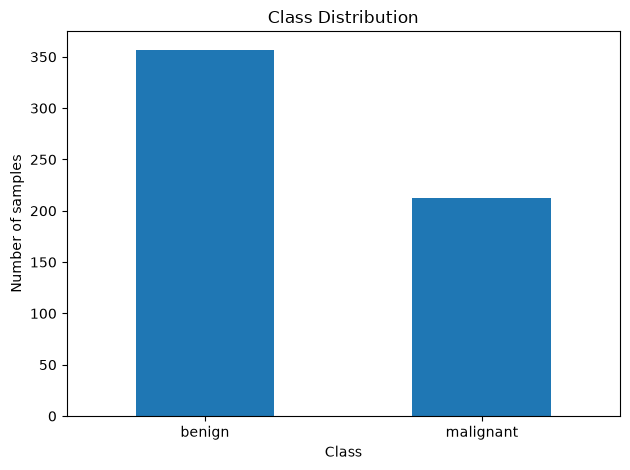

In [53]:
print("Missing values in dataset:", int(X.isna().sum().sum()))
print("\nFeature summary:")
display(X.describe().T.head(10))

class_counts = y.map(target_names).value_counts()
class_counts.plot(kind="bar", rot=0)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

## 4. Split into training and testing sets

The test set is held out until evaluation. Stratification keeps the class proportions similar in both sets.

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


## 5. Train the models

In [55]:
# Logistic Regression benefits from feature scaling, so use a pipeline.
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

# Random Forest does not require feature scaling.
forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

logistic_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


## 6. Evaluate model performance

In [56]:
def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

results = pd.DataFrame([
    evaluate_model(logistic_model, X_test, y_test, "Logistic Regression"),
    evaluate_model(forest_model, X_test, y_test, "Random Forest")
]).set_index("Model")

display(results.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.982,0.986,0.986,0.986,0.995
Random Forest,0.939,0.958,0.944,0.951,0.994


## 7. Confusion matrix and classification report

Model selected by F1-score: Logistic Regression

Classification report (0 = malignant, 1 = benign):
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



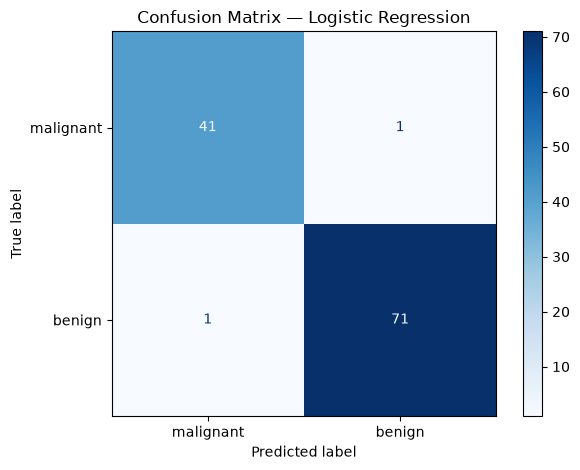

In [57]:
best_model_name = results["F1-score"].idxmax()
best_model = logistic_model if best_model_name == "Logistic Regression" else forest_model
y_pred = best_model.predict(X_test)

print("Model selected by F1-score:", best_model_name)
print("\nClassification report (0 = malignant, 1 = benign):")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["malignant", "benign"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 8. Compare ROC curves

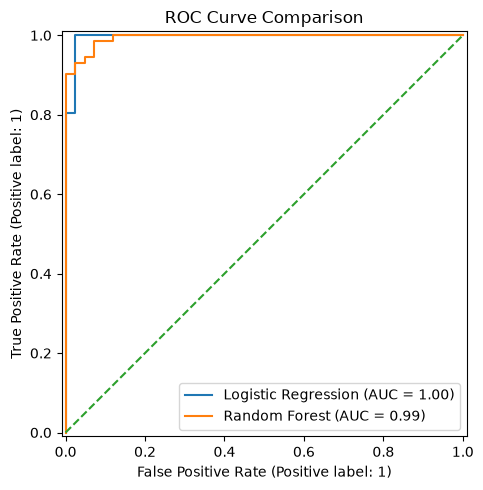

In [58]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(logistic_model, X_test, y_test, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_estimator(forest_model, X_test, y_test, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

## 9. Feature importance (Random Forest)

,Importance
worst perimeter,0.150294
worst area,0.136401
mean concave points,0.106040
worst concave points,0.099206
worst radius,0.074967
mean concavity,0.058505
mean radius,0.052490
mean perimeter,0.040005
worst concavity,0.039076
mean area,0.037216


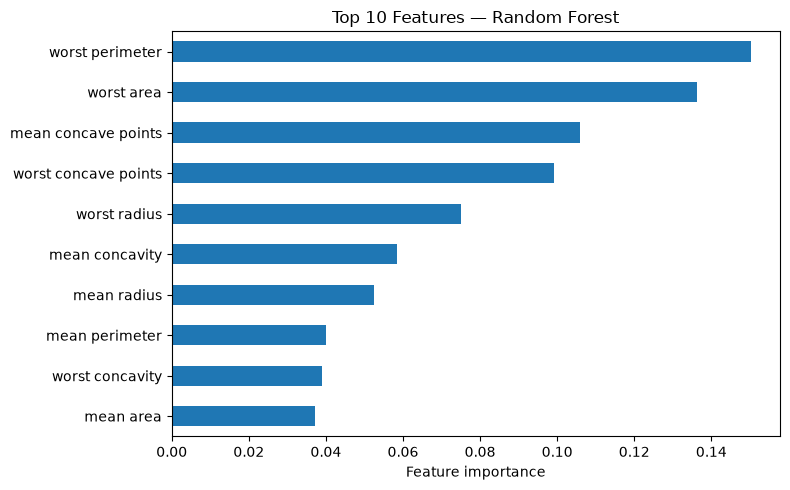

In [59]:
importances = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importances.head(10).to_frame("Importance"))

importances.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Features — Random Forest")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

## 10. Try a sample prediction

The example below uses one row from the held-out test set. The displayed prediction is only for demonstrating the code and is not a medical conclusion.

In [60]:
sample = X_test.iloc[[0]]
actual_label = int(y_test.iloc[0])
predicted_label = int(best_model.predict(sample)[0])
predicted_probability = float(best_model.predict_proba(sample)[0, 1])

print("Actual class:", target_names[actual_label])
print("Predicted class:", target_names[predicted_label])
print(f"Model probability for benign class: {predicted_probability:.3f}")

Actual class: malignant
Predicted class: malignant
Model probability for benign class: 0.000


## 11. Conclusion

This project demonstrates a complete binary-classification workflow using two algorithms: Logistic Regression and Random Forest. The evaluation table compares accuracy, precision, recall, F1-score, and ROC-AUC. The confusion matrix shows the types of correct and incorrect predictions, while the ROC curve compares discrimination performance.

**Important:** Results depend on the selected dataset, train/test split, and model settings. This notebook is intended for learning machine learning concepts only.

### How to run
1. Install Python 3.10+ and Jupyter Notebook, or open the notebook in Google Colab.
2. Install dependencies with `pip install -r requirements.txt`.
3. Open `Binary_Classification.ipynb`.
4. Run the cells from top to bottom.